# IV. Evaluate Model

In [3]:
import math
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

In [4]:
import sys
sys.path.append('scripts')

In [5]:
from tensorflow.keras.models import load_model
from keras.optimizers import Adam

In [6]:
from utilities import create_groups, split_lstm_input

In [7]:
plt.style.use('seaborn-v0_8')

In [8]:
train = pd.read_csv('data\Train_BTC.csv')
test = pd.read_csv('data\Test_BTC.csv')
print(f'len of train: {len(train)}, len of test: {len(test)}')
print(f'iso_week of train: {train.iso_month.nunique()}, iso_week of test: {test.iso_month.nunique()}')

len of train: 432, len of test: 108
iso_week of train: 100, iso_week of test: 27


In [9]:
train_data = create_groups(train['close_point_relative_normalization'].values,4)
test_data = create_groups(test['close_point_relative_normalization'].values, 4)

In [17]:
model = load_model('real_bitcoin_lstm_v0_me.keras', compile=False)
model.compile(optimizer=Adam(), loss="mean_squared_error")
model.optimizer.get_config()

{'name': 'adam',
 'learning_rate': 0.0010000000474974513,
 'weight_decay': None,
 'clipnorm': None,
 'global_clipnorm': None,
 'clipvalue': None,
 'use_ema': False,
 'ema_momentum': 0.99,
 'ema_overwrite_frequency': None,
 'loss_scale_factor': None,
 'gradient_accumulation_steps': None,
 'beta_1': 0.9,
 'beta_2': 0.999,
 'epsilon': 1e-07,
 'amsgrad': False}

In [18]:
combined_set = np.concatenate((train_data, test_data), axis=1)
combined_set.shape

(1, 135, 4)

In [19]:
evaluated_weeks = []
for i in range(0, test_data.shape[1]):
    input_series = combined_set[0:,i:i+107]

    X_test = input_series[0:,:-1].reshape(1, input_series.shape[1] - 1, 4)
    Y_test = input_series[0:,-1:][0]
    
    result = model.evaluate(x=X_test, y=Y_test, verbose=0)
    evaluated_weeks.append(result)

In [20]:
evaluated_weeks

[0.001432953984476626,
 0.010330485180020332,
 0.0814184844493866,
 0.003302727360278368,
 0.03506726771593094,
 0.005412653554230928,
 0.008657959289848804,
 0.013819407671689987,
 0.0012522416654974222,
 0.008318805135786533,
 0.0041535780765116215,
 0.003218922531232238,
 0.02524232119321823,
 0.0023211759980767965,
 0.004728418309241533,
 0.0043024043552577496,
 0.0223692674189806,
 0.0010889827972278,
 0.007042349316179752,
 0.005385059863328934,
 0.007401479408144951,
 0.020346779376268387,
 0.0022282530553638935,
 0.006860491819679737,
 0.013472598046064377,
 0.0038310049567371607,
 0.014169489964842796]

Text(0, 0.5, 'MSE')

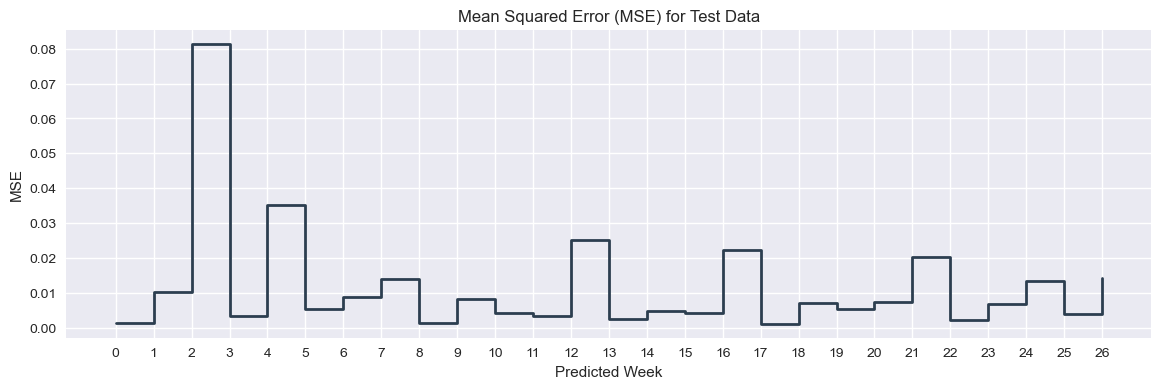

In [21]:
ax = pd.Series(evaluated_weeks).plot(drawstyle="steps-post",
                                     figsize=(14,4),
                                     linewidth=2,
                                     color='#2c3e50',
                                     grid=True,
                                     title='Mean Squared Error (MSE) for Test Data')

y = [i for i in range(0, len(evaluated_weeks))]
yint = range(min(y), math.ceil(max(y))+1)
plt.xticks(yint)

ax.set_xlabel("Predicted Week")
ax.set_ylabel("MSE")

In [22]:
predicted_month = []

for i in range(0, test_data.shape[1]):
    input_series = combined_set[0:,i:i+107]
    predicted_month.append(model.predict(input_series))
    
    
predicted_week = []
for week in predicted_month:
    predicted_week += list(week[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 393ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━

In [24]:
combined = pd.concat([train, test])

In [25]:
last_week = datetime.strptime(train['date'].max(), '%Y-%m-%d')
list_of_week = []

for week in range(1, len(predicted_week) + 1):
    W = (last_week + timedelta(weeks=week)).strftime('%Y-%m-%d')
    list_of_week.append(W)
print(len(list_of_week))

108


In [27]:
predicted = pd.DataFrame({
    'date': list_of_week, 
    'close_point_relative_normalization': predicted_week
})

In [28]:
combined['date'] = combined['date'].apply(lambda x: datetime.strptime(x, '%Y-%m-%d'))
predicted['date'] = predicted['date'].apply(lambda x: datetime.strptime(x, '%Y-%m-%d'))
predicted.isnull().sum()

date                                  0
close_point_relative_normalization    0
dtype: int64

In [29]:
observed = combined[combined['date'] > train['date'].max()]

In [30]:
def plot_two_series(A, B, variable, title):
   
    plt.figure(figsize=(14,4))
    plt.xlabel('Real and predicted')

    ax1 = A.set_index('date')[variable].plot(
        linewidth=2, color='#d35400', grid=True, label='Observed', title=title)

    ax2 = B.set_index('date')[variable].plot(
        linewidth=2, color='grey', grid=True, label='Predicted')
    
    ax1.set_xlabel("Predicted Week")
    ax1.set_ylabel("Predicted Values")

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()

    plt.legend(l1+l2, loc=2)
    plt.savefig("BTC_USD-w.png")
    plt.show()

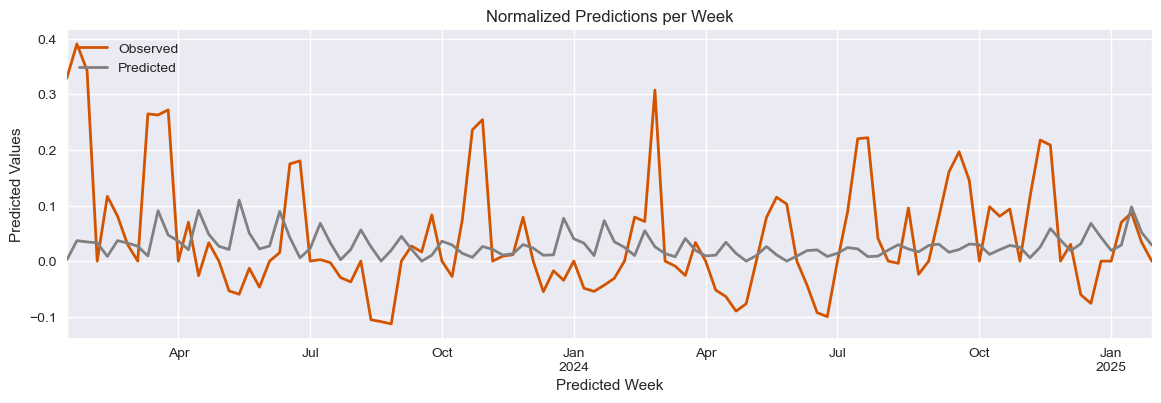

In [31]:
plot_two_series(observed, predicted, 
                variable='close_point_relative_normalization',
                title='Normalized Predictions per Week')

In [32]:
data = pd.to_datetime(predicted['date']).dt.isocalendar()
data['month'] = pd.to_datetime(predicted['date']).dt.month
df = data
df['year'] = df['year'].astype(str)
df['month'] = df['month'].astype(str)
df['a'] = df['year'] + '-' + df['month']
predicted['iso_month'] = df['a']

In [33]:
def denormalize(reference, series, 
                normalized_variable='close_point_relative_normalization',
                denormalized_variable='close'):
   
    if('iso_month' in list(series.columns)):
    
        week_values = reference[reference['iso_month'] == series['iso_month'].values[0]]
        last_value = week_values[denormalized_variable].values[0]
        series[denormalized_variable] = last_value * (series[normalized_variable] + 1)


    return series

In [34]:
predicted_close = predicted.groupby('iso_month', group_keys=False).apply(lambda x: denormalize(observed, x))

C:\Users\hamid\AppData\Local\Temp\ipykernel_17928\1882013529.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  predicted_close = predicted.groupby('iso_month', group_keys=False).apply(lambda x: denormalize(observed, x))


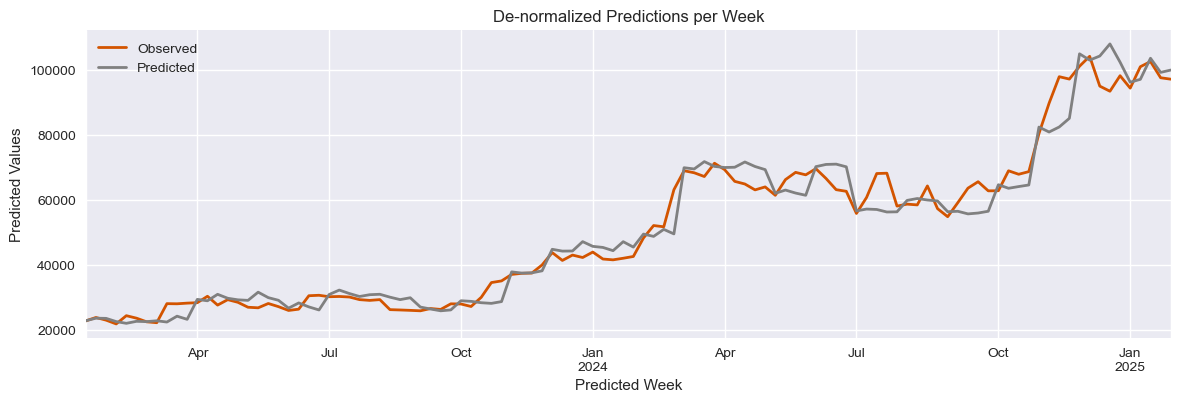

In [35]:
plot_two_series(observed, predicted_close, 
                variable='close',
                title='De-normalized Predictions per Week')

In [36]:
from utilities import rmse, mape

In [37]:
print('Normalized RMSE: {:.2f}'.format(
    rmse(observed['close_point_relative_normalization'][:-3], 
         predicted_close['close_point_relative_normalization'].reset_index(drop=True))))

Normalized RMSE: 0.11


In [38]:
print('De-normalized RMSE: ${:.1f} USD'.format(
    rmse(observed['close'][:-3], 
         predicted_close['close'].reset_index(drop=True))))

print('De-normalized MAPE: {:.1f}%'.format(
    mape(observed['close'][:-3], 
         predicted_close['close'].reset_index(drop=True))))

De-normalized RMSE: $4789.4 USD
De-normalized MAPE: 6.9%
